In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


Load Dataset

In [11]:
import os

print(os.listdir('/content'))

['.config', 'sample_data']


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv('/content/sample_data/Titanic/train.csv')
test = pd.read_csv('/content/sample_data/Titanic/test.csv')
submission = pd.read_csv('/content/sample_data/Titanic/gender_submission.csv')

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [13]:
import os

print("Current directory contents:")
print(os.listdir('/content'))

Current directory contents:
['.config', 'sample_data']


In [14]:
print("Training dataset:", train.shape)
print("Testing dataset:", test.shape)
print("Submission dataset:", submission.shape)

Training dataset: (891, 12)
Testing dataset: (418, 11)
Submission dataset: (418, 2)


In [15]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [16]:
print("Training data:", train.shape)
print("Testing data:", test.shape)
print("Submission data:", submission.shape)

Training data: (891, 12)
Testing data: (418, 11)
Submission data: (418, 2)


In [17]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [18]:
missing = train.isnull().sum()

print(missing[missing > 0])

Age         177
Cabin       687
Embarked      2
dtype: int64


In [19]:
# Overall survival distribution
print("Survival distribution:")
print(train['Survived'].value_counts())

print("\nSurvival percentages:")
print(train['Survived'].value_counts(normalize=True) * 100)

Survival distribution:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


In [20]:
gender_survival = pd.crosstab(train['Sex'], train['Survived'])

print("Survival counts:")
print(gender_survival)

print("\nSurvival rate by gender:")
print((train.groupby('Sex')['Survived'].mean() * 100).round(2))

Survival counts:
Survived    0    1
Sex               
female     81  233
male      468  109

Survival rate by gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


In [21]:
# Survival counts by passenger class
class_survival = pd.crosstab(
    train['Pclass'],
    train['Survived']
)

print("Survival counts by passenger class:")
print(class_survival)

print("\nSurvival rate by passenger class:")
print(
    (train.groupby('Pclass')['Survived'].mean() * 100).round(2)
)

Survival counts by passenger class:
Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119

Survival rate by passenger class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


In [22]:
print("Age statistics by survival status:")

print(
    train.groupby('Survived')['Age']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
)

Age statistics by survival status:
          count   mean  median   min   max
Survived                                  
0           424  30.63    28.0  1.00  74.0
1           290  28.34    28.0  0.42  80.0


In [23]:
train['AgeGroup'] = pd.cut(
    train['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teenager', 'Young Adult', 'Adult', 'Senior']
)

age_survival = train.groupby(
    'AgeGroup', observed=False
)['Survived'].agg(['count', 'mean'])

age_survival['mean'] *= 100

print(age_survival.round(2))

             count   mean
AgeGroup                 
Child           69  57.97
Teenager        70  42.86
Young Adult    358  38.27
Adult          195  40.00
Senior          22  22.73


In [24]:
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1

family_survival = train.groupby(
    'FamilySize'
)['Survived'].agg(['count', 'mean'])

family_survival['mean'] *= 100

print(family_survival.round(2))

            count   mean
FamilySize              
1             537  30.35
2             161  55.28
3             102  57.84
4              29  72.41
5              15  20.00
6              22  13.64
7              12  33.33
8               6   0.00
11              7   0.00


In [25]:
# Survival by embarkation point
embarked_survival = train.groupby(
    'Embarked'
)['Survived'].agg(['count', 'mean'])

embarked_survival['mean'] *= 100

print(embarked_survival.round(2))

          count   mean
Embarked              
C           168  55.36
Q            77  38.96
S           644  33.70


In [26]:
# Compare ticket fares by survival status

fare_analysis = train.groupby('Survived')['Fare'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

print(fare_analysis.round(2))

          count   mean  median  min     max
Survived                                   
0           549  22.12    10.5  0.0  263.00
1           342  48.40    26.0  0.0  512.33


## 4.7 Ticket Fare Analysis

### Objective
Investigate the relationship between ticket fare and passenger survival.

We compare the mean, median, minimum and maximum fares for passengers who survived and those who did not.

### Findings
- The average fare among survivors was 48.40.
- The average fare among non-survivors was 22.12.
- The median fare among survivors was 26.00.
- The median fare among non-survivors was 10.50.

### Interpretation
Passengers who survived generally paid higher ticket fares.

This suggests that Fare may contain useful predictive information. However, the relationship may be influenced by passenger class and other variables. Further investigation is required before drawing conclusions.

| Feature | Main observation |
|---|---|
| Survival distribution | 38.38% survived |
| Gender | Females had higher survival |
| Passenger class | First-class passengers had higher survival |
| Age | Children had higher survival |
| Family size | Small families generally had higher survival |
| Embarkation | Cherbourg had the highest survival rate |
| Fare | Survivors generally paid higher fares |

## 5. Numerical Feature Correlation Analysis

### Objective
Investigate relationships between numerical variables in the training dataset.

Correlation analysis helps identify relationships between features and the target variable.

We will use a correlation matrix and heatmap to visualise these relationships.

Note: Correlation does not imply causation.

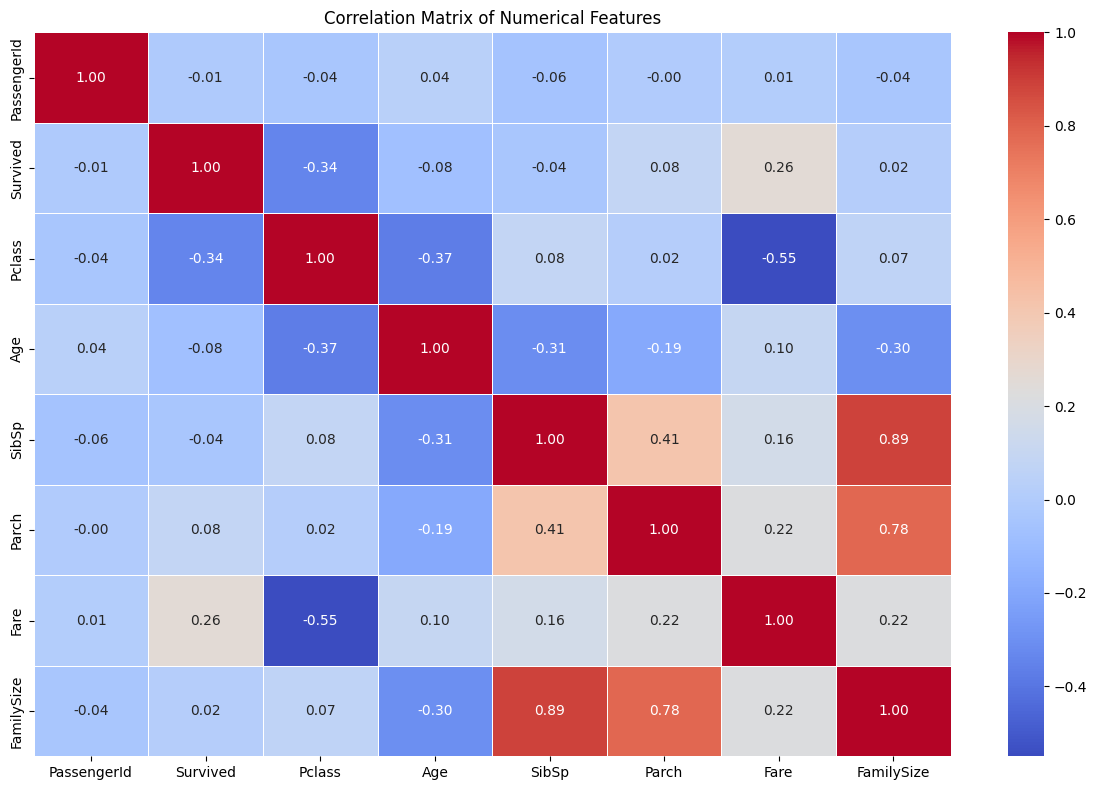

In [27]:
# Select numerical columns
numerical_features = train.select_dtypes(include=['int64', 'float64'])

# Calculate correlation matrix
correlation_matrix = numerical_features.corr()

# Display heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

| Feature | Correlation with survival | Interpretation |
|---|---:|---|
| Pclass | -0.34 | Moderate negative relationship |
| Fare | +0.26 | Positive relationship |
| Parch | +0.08 | Very weak positive relationship |
| Age | -0.08 | Very weak negative relationship |
| SibSp | -0.04 | Almost no linear relationship |
| FamilySize | +0.02 | Almost no linear relationship |

| Feature relationship | Correlation |
|---|---:|
| SibSp and FamilySize | 0.89 |
| Parch and FamilySize | 0.78 |
| Pclass and Fare | -0.55 |
| SibSp and Parch | 0.41 |

## 5.1 Numerical Feature Correlation Analysis

### Objective
Investigate the relationships between numerical variables in the Titanic training dataset using Pearson correlation.

### Key Findings

- Pclass has a negative correlation with survival (-0.34).
- Fare has a positive correlation with survival (0.26).
- Age has a weak negative linear correlation with survival (-0.08).
- FamilySize has a strong correlation with SibSp (0.89) and Parch (0.78).
- Pclass and Fare have a negative correlation (-0.55).

### Interpretation

Passenger class and ticket fare demonstrate the strongest linear relationships with survival among the numerical features examined.

FamilySize is strongly correlated with SibSp and Parch because it is derived from these variables.

This suggests potential redundancy when including all three features in certain models.

Age has a weak linear correlation with survival, but previous age-group analysis suggests that its relationship with survival may not be entirely linear.

### Limitations

Pearson correlation measures linear relationships and does not establish causation. It also does not capture every possible nonlinear relationship between variables.

Further investigation through feature engineering, model evaluation and feature importance analysis will help determine the predictive usefulness of these variables.

## 5.2 Data Quality Assessment

### Objective

Examine missing values, duplicate records and data types in the training and testing datasets.

This assessment will guide our preprocessing decisions and help prevent errors during model development.

In [28]:
# Inspect training and testing data types

print("TRAINING DATA INFORMATION")
train.info()

print("\nTESTING DATA INFORMATION")
test.info()

TRAINING DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  891 non-null    int64   
 1   Survived     891 non-null    int64   
 2   Pclass       891 non-null    int64   
 3   Name         891 non-null    object  
 4   Sex          891 non-null    object  
 5   Age          714 non-null    float64 
 6   SibSp        891 non-null    int64   
 7   Parch        891 non-null    int64   
 8   Ticket       891 non-null    object  
 9   Fare         891 non-null    float64 
 10  Cabin        204 non-null    object  
 11  Embarked     889 non-null    object  
 12  AgeGroup     714 non-null    category
 13  FamilySize   891 non-null    int64   
dtypes: category(1), float64(2), int64(6), object(5)
memory usage: 91.7+ KB

TESTING DATA INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data co

In [29]:
# Check missing values in both datasets

print("TRAINING DATA MISSING VALUES")
print(train.isnull().sum())

print("\nTESTING DATA MISSING VALUES")
print(test.isnull().sum())

TRAINING DATA MISSING VALUES
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
AgeGroup       177
FamilySize       0
dtype: int64

TESTING DATA MISSING VALUES
PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64


In [30]:
# Check duplicate records

print("Training duplicates:", train.duplicated().sum())
print("Testing duplicates:", test.duplicated().sum())

Training duplicates: 0
Testing duplicates: 0


| Dataset | Rows | Columns |
|---|---:|---:|
| Training | 891 | 14 |
| Testing | 418 | 11 |

| Feature | Training missing | Testing missing |
|---|---:|---:|
| Age | 177 | 86 |
| Cabin | 687 | 327 |
| Embarked | 2 | 0 |
| Fare | 0 | 1 |
| AgeGroup | 177 | Not created |

Our interpretation
Age

Missing ages occur in both datasets. We should investigate an appropriate imputation strategy, potentially using passenger titles and passenger class rather than simply filling every missing age with the overall median.

Cabin

A substantial proportion of cabin information is missing. Instead of immediately discarding the entire feature, we can extract whether a cabin was recorded and investigate its deck information.

Embarked

Only two training observations are missing. We can impute these using the most frequent embarkation point, learned from the training data.

Fare

One testing observation has a missing fare. We'll investigate an appropriate imputation strategy using training data.

Training duplicates: 0
Testing duplicates: 0

## 5.2 Data Quality Assessment

### Objective

Assess the structure, data types, missing values and duplicate records in the training and testing datasets before preprocessing.

### Dataset Structure

- Training dataset: 891 observations and 14 columns.
- Testing dataset: 418 observations and 11 columns.

The training dataset contains two additional engineered features: AgeGroup and FamilySize.

### Missing-Value Findings

The training dataset contains:
- Age: 177 missing values.
- Cabin: 687 missing values.
- Embarked: 2 missing values.
- AgeGroup: 177 missing values.

The testing dataset contains:
- Age: 86 missing values.
- Cabin: 327 missing values.
- Fare: 1 missing value.

### Duplicate Analysis

No exact duplicate records were identified in either dataset.

### Preprocessing Considerations

1. Investigate age imputation using relevant passenger characteristics.
2. Extract useful information from the Cabin feature before deciding whether to retain it.
3. Impute missing Embarked values.
4. Investigate and impute the missing Fare value in the testing dataset.
5. Ensure engineered features are generated consistently in both datasets.

### Conclusion

The datasets contain missing values that require careful treatment before model development. Preprocessing decisions will be learned from the training data and applied consistently to validation and testing data to prevent data leakage.

| Feature | Information we want to extract |
|---|---|
| Name | Passenger title: Mr, Mrs, Miss, Master, etc. |
| Ticket | Shared ticket groups and ticket characteristics |
| Cabin | Deck information and cabin-record availability |

## 5.3 Feature Engineering: Passenger Titles

### Objective

Extract passenger titles from the Name column.

Passenger titles may provide information about gender, age group, marital status and social position.

We will investigate the distribution of titles and their relationship with passenger survival.

This feature will also be useful when developing a more informed age-imputation strategy.

In [31]:
# Extract titles from passenger names

train['Title'] = train['Name'].str.extract(
    r',\s*([^.]*)\.',
    expand=False
).str.strip()

# Examine title distribution
print("Passenger title distribution:")
print(train['Title'].value_counts())

# Examine survival by title
print("\nSurvival rate by title:")
print(
    (train.groupby('Title')['Survived'].mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

Passenger title distribution:
Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

Survival rate by title:
Title
Lady            100.00
Ms              100.00
Sir             100.00
Mme             100.00
the Countess    100.00
Mlle            100.00
Mrs              79.20
Miss             69.78
Master           57.50
Major            50.00
Col              50.00
Dr               42.86
Mr               15.67
Capt              0.00
Jonkheer          0.00
Don               0.00
Rev               0.00
Name: Survived, dtype: float64


A. Gender and social status
- Mr passengers had a survival rate of only 15.67%.
- Mrs passengers had a survival rate of 79.20%.
- Miss passengers had a survival rate of 69.78%.
This reinforces our earlier gender analysis.
B. The Master title
Master passengers had a survival rate of 57.50%.

Historically, Master was commonly used for boys. This title may help us identify younger male passengers.

This is particularly interesting because we also have missing age values.
C. Rare titles
Some titles have 100% or 0% survival rates.

However, we must be careful.

For example, Lady, Sir and Mme each have very few observations. A 100% survival rate based on one passenger does not establish a reliable pattern.

## 5.4 Passenger Title Consolidation

### Objective

Reduce categorical complexity by grouping uncommon passenger titles into a single Rare category.

The four most frequent titles (Mr, Mrs, Miss and Master) will be retained separately.

All other titles will be grouped into Rare.

This transformation will help reduce sparsity when encoding categorical features for machine learning.

In [32]:
# Group uncommon titles

common_titles = ['Mr', 'Mrs', 'Miss', 'Master']

train['Title'] = train['Title'].apply(
    lambda title: title if title in common_titles else 'Rare'
)

# Examine the new distribution
print("Consolidated title distribution:")
print(train['Title'].value_counts())

# Examine survival rates
print("\nSurvival rate by consolidated title:")

print(
    (train.groupby('Title')['Survived'].mean() * 100)
    .round(2)
)

Consolidated title distribution:
Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

Survival rate by consolidated title:
Title
Master    57.50
Miss      69.78
Mr        15.67
Mrs       79.20
Rare      44.44
Name: Survived, dtype: float64


## 5.5 Feature Engineering: Cabin Deck Extraction

### Objective

Extract the deck identifier from the Cabin column.

The original Cabin feature contains substantial missing information. However, the available records may contain useful information about passenger accommodation.

We will extract the first character of each recorded cabin identifier and investigate its relationship with survival.

In [33]:
# Extract cabin deck

train['Deck'] = train['Cabin'].str[0]

# Examine deck distribution
print("Cabin deck distribution:")
print(train['Deck'].value_counts(dropna=False))

# Examine survival by deck
print("\nSurvival rate by deck:")

print(
    (train.groupby('Deck', dropna=False)['Survived'].mean() * 100)
    .round(2)
)

Cabin deck distribution:
Deck
NaN    687
C       59
B       47
D       33
E       32
A       15
F       13
G        4
T        1
Name: count, dtype: int64

Survival rate by deck:
Deck
A      46.67
B      74.47
C      59.32
D      75.76
E      75.00
F      61.54
G      50.00
T       0.00
NaN    29.99
Name: Survived, dtype: float64


| Deck | Passengers | Survival rate |
|---|---:|---:|
| A | 15 | 46.67% |
| B | 47 | 74.47% |
| C | 59 | 59.32% |
| D | 33 | 75.76% |
| E | 32 | 75.00% |
| F | 13 | 61.54% |
| G | 4 | 50.00% |
| T | 1 | 0.00% |
| Missing | 687 | 29.99% |

## 5.6 Cabin Feature Transformation

### Objective

Create a categorical representation of cabin deck while preserving missing cabin information as an explicit category.

This allows us to investigate whether having recorded cabin information itself carries predictive value.

In [34]:
# Create a cabin deck feature with missing values represented as Unknown

train['Deck'] = train['Cabin'].str[0].fillna('Unknown')

# Examine the updated distribution
print("Cabin deck distribution:")
print(train['Deck'].value_counts())

# Examine survival rates
print("\nSurvival rates by cabin deck:")

print(
    (train.groupby('Deck')['Survived'].mean() * 100)
    .round(2)
)

Cabin deck distribution:
Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

Survival rates by cabin deck:
Deck
A          46.67
B          74.47
C          59.32
D          75.76
E          75.00
F          61.54
G          50.00
T           0.00
Unknown    29.99
Name: Survived, dtype: float64


## 5.7 Feature Engineering: Ticket Information

### Objective

Investigate the Ticket column to identify patterns that may contain predictive information.

Ticket identifiers may contain prefixes that distinguish ticket groups or booking characteristics.

We will extract ticket prefixes and examine their frequency and relationship with passenger survival.

In [35]:
# Extract ticket prefixes

train['TicketPrefix'] = (
    train['Ticket']
    .astype(str)
    .str.replace(r'[./]', '', regex=True)
    .str.replace(r'\s+', '', regex=True)
    .str.extract(r'([A-Za-z]+)', expand=False)
    .fillna('Numeric')
    .str.upper()
)

# Examine ticket prefix distribution

print("Ticket prefix distribution:")

print(train['TicketPrefix'].value_counts().head(20))

Ticket prefix distribution:
TicketPrefix
NUMERIC    661
PC          60
CA          41
A           28
STONO       18
SOTONOQ     15
SCPARIS     11
WC          10
SOC          6
FCC          5
C            5
LINE         4
PP           3
WEP          3
SOPP         3
PPP          2
SOTONO       2
SCAH         2
SWPP         2
SCA          1
Name: count, dtype: int64


In [36]:
# Survival rate by ticket prefix

ticket_analysis = train.groupby(
    'TicketPrefix'
)['Survived'].agg(['count', 'mean'])

ticket_analysis['mean'] *= 100

print(ticket_analysis.sort_values(
    'count', ascending=False
).round(2))

              count    mean
TicketPrefix               
NUMERIC         661   38.43
PC               60   65.00
CA               41   34.15
A                28    7.14
STONO            18   44.44
SOTONOQ          15   13.33
SCPARIS          11   45.45
WC               10   10.00
SOC               6   16.67
FCC               5   80.00
C                 5   40.00
LINE              4   25.00
PP                3   66.67
WEP               3   33.33
SOPP              3    0.00
SWPP              2  100.00
SCAH              2   50.00
PPP               2   50.00
SOTONO            2    0.00
AS                1    0.00
CASOTON           1    0.00
FC                1    0.00
FA                1    0.00
SOP               1    0.00
SCAHBASLE         1  100.00
SC                1  100.00
SCOW              1    0.00
SCA               1    0.00
SP                1    0.00


## 5.8 Ticket Prefix Consolidation

### Objective

Reduce categorical complexity in the extracted TicketPrefix feature.

Common ticket prefixes will be retained, while uncommon prefixes will be grouped into a RARE category.

Numeric-only ticket identifiers will remain classified as NUMERIC.

This transformation aims to reduce sparse categorical representations and improve model generalisation.

In [37]:
# Identify frequent ticket prefixes

prefix_counts = train['TicketPrefix'].value_counts()

# Retain prefixes appearing at least 10 times
common_prefixes = prefix_counts[
    prefix_counts >= 10
].index

# Group uncommon prefixes
train['TicketPrefixGroup'] = train['TicketPrefix'].apply(
    lambda x: x if x in common_prefixes else 'RARE'
)

# Examine consolidated distribution
print("Consolidated ticket prefix distribution:")

print(train['TicketPrefixGroup'].value_counts())

# Examine survival rates
print("\nSurvival rate by ticket prefix group:")

print(
    (train.groupby('TicketPrefixGroup')['Survived'].mean() * 100)
    .round(2)
)

Consolidated ticket prefix distribution:
TicketPrefixGroup
NUMERIC    661
PC          60
RARE        47
CA          41
A           28
STONO       18
SOTONOQ     15
SCPARIS     11
WC          10
Name: count, dtype: int64

Survival rate by ticket prefix group:
TicketPrefixGroup
A           7.14
CA         34.15
NUMERIC    38.43
PC         65.00
RARE       36.17
SCPARIS    45.45
SOTONOQ    13.33
STONO      44.44
WC         10.00
Name: Survived, dtype: float64


## 5.9 Shared Ticket Analysis

### Objective

Investigate the frequency of ticket identifiers and determine whether passengers sharing a ticket number demonstrate different survival patterns.

Shared tickets may provide information about travelling groups and passenger relationships.

In [38]:
# Calculate the number of passengers sharing each ticket

train['TicketGroupSize'] = train.groupby(
    'Ticket'
)['Ticket'].transform('count')

# Examine ticket group sizes
print("Ticket group size distribution:")

print(train['TicketGroupSize'].value_counts().sort_index())

# Survival rate by ticket group size
print("\nSurvival rate by ticket group size:")

print(
    (train.groupby('TicketGroupSize')['Survived'].mean() * 100)
    .round(2)
)

Ticket group size distribution:
TicketGroupSize
1    547
2    188
3     63
4     44
5     10
6     18
7     21
Name: count, dtype: int64

Survival rate by ticket group size:
TicketGroupSize
1    29.80
2    57.45
3    69.84
4    50.00
5     0.00
6     0.00
7    23.81
Name: Survived, dtype: float64


### Travel Group Analysis

Passengers travelling alone may have had different survival outcomes from passengers travelling in groups.

We will use the ticket group size to classify passengers into three categories:
- Alone: travelling on a ticket by themselves.
- Small Group: travelling with 2–3 passengers on the same ticket.
- Large Group: travelling with 4 or more passengers on the same ticket.

We will examine whether travel group size is associated with survival.

In [39]:
def classify_ticket_group(size):
    if size == 1:
        return 'Alone'
    elif size <= 3:
        return 'Small Group'
    else:
        return 'Large Group'


train['TravelGroup'] = train['TicketGroupSize'].apply(
    classify_ticket_group
)

print("Travel group distribution:")
print(train['TravelGroup'].value_counts())

print("\nSurvival rate by travel group:")
print(
    (train.groupby('TravelGroup')['Survived'].mean() * 100)
    .round(2)
)

Travel group distribution:
TravelGroup
Alone          547
Small Group    251
Large Group     93
Name: count, dtype: int64

Survival rate by travel group:
TravelGroup
Alone          29.80
Large Group    29.03
Small Group    60.56
Name: Survived, dtype: float64


## Data Preparation for Machine Learning

Before developing predictive models, we need to prepare our datasets.

This stage involves:
- Separating the target variable from the training features.
- Excluding identifiers and columns that should not be used directly for prediction.
- Ensuring training and test datasets have consistent features.
- Preparing a preprocessing pipeline for missing values and categorical variables.

All learned preprocessing operations will be fitted using training data only to prevent data leakage.

### Reusable Feature Engineering Function

We will create a function that applies the same feature transformations to both the training and test datasets.

The function will extract useful information from passenger names, cabin numbers and ticket numbers, while creating additional features such as family size and travel group.

This ensures consistency between model training and prediction.

In [40]:
def engineer_features(df):

    df = df.copy()

    # 1. Extract passenger title
    df['Title'] = df['Name'].str.extract(
        r',\s*([^.]*)\.',
        expand=False
    ).str.strip()

    common_titles = ['Mr', 'Mrs', 'Miss', 'Master']

    df['Title'] = df['Title'].apply(
        lambda x: x if x in common_titles else 'Rare'
    )

    # 2. Extract cabin deck
    df['Deck'] = df['Cabin'].str[0].fillna('Unknown')

    # 3. Extract ticket prefix
    df['TicketPrefix'] = (
        df['Ticket']
        .astype(str)
        .str.replace(r'[./]', '', regex=True)
        .str.replace(r'\s+', '', regex=True)
        .str.extract(r'([A-Za-z]+)', expand=False)
        .fillna('Numeric')
        .str.upper()
    )

    # 4. Group uncommon ticket prefixes
    common_prefixes = [
        'NUMERIC', 'PC', 'CA', 'A',
        'STONO', 'SOTONOQ', 'SCPARIS', 'WC'
    ]

    df['TicketPrefixGroup'] = df['TicketPrefix'].apply(
        lambda x: x if x in common_prefixes else 'RARE'
    )

    # 5. Family size
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

    # 6. Ticket group size
    # Calculate using the available training and test records together.
    df['TicketGroupSize'] = df.groupby(
        'Ticket'
    )['Ticket'].transform('count')

    # 7. Travel group
    def classify_ticket_group(size):
        if size == 1:
            return 'Alone'
        elif size <= 3:
            return 'Small Group'
        else:
            return 'Large Group'

    df['TravelGroup'] = df['TicketGroupSize'].apply(
        classify_ticket_group
    )

    return df

In [41]:
# Combine temporarily to calculate ticket group sizes consistently
combined = pd.concat(
    [train.drop(columns=['Survived']), test],
    ignore_index=True
)

combined_engineered = engineer_features(combined)

# Separate training and test datasets again
train_engineered = combined_engineered.iloc[:len(train)].copy()
test_engineered = combined_engineered.iloc[len(train):].copy()

# Restore the target variable
train_engineered['Survived'] = train['Survived'].values

print("Training dataset shape:", train_engineered.shape)
print("Test dataset shape:", test_engineered.shape)

Training dataset shape: (891, 20)
Test dataset shape: (418, 19)


In [42]:
print("Training engineered columns:")
print(train_engineered.columns.tolist())

print("\nTest engineered columns:")
print(test_engineered.columns.tolist())

print("\nMissing values in training data:")
print(train_engineered.isnull().sum())

print("\nMissing values in test data:")
print(test_engineered.isnull().sum())

Training engineered columns:
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'AgeGroup', 'FamilySize', 'Title', 'Deck', 'TicketPrefix', 'TicketPrefixGroup', 'TicketGroupSize', 'TravelGroup', 'Survived']

Test engineered columns:
['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'AgeGroup', 'FamilySize', 'Title', 'Deck', 'TicketPrefix', 'TicketPrefixGroup', 'TicketGroupSize', 'TravelGroup']

Missing values in training data:
PassengerId            0
Pclass                 0
Name                   0
Sex                    0
Age                  177
SibSp                  0
Parch                  0
Ticket                 0
Fare                   0
Cabin                687
Embarked               2
AgeGroup             177
FamilySize             0
Title                  0
Deck                   0
TicketPrefix           0
TicketPrefixGroup      0
TicketGroupSize        0
TravelGroup

## Feature Selection and Target Separation

We will separate the target variable (Survived) from the independent variables.

PassengerId will be retained separately for Kaggle submission but excluded from model training.

We will initially exclude raw Name, Ticket and Cabin columns because useful information has already been extracted from them.

AgeGroup will also be excluded because it has not yet been consistently engineered for both datasets.

In [43]:
# Define target variable
y = train_engineered['Survived']

# Define columns to exclude
drop_columns = [
    'PassengerId',
    'Survived',
    'Name',
    'Ticket',
    'Cabin',
    'AgeGroup'
]

# Create feature datasets
X = train_engineered.drop(columns=drop_columns)
X_test = test_engineered.drop(columns=[
    col for col in drop_columns if col in test_engineered.columns
])

# Preserve passenger IDs for submission
test_passenger_ids = test_engineered['PassengerId']

print("Training features shape:", X.shape)
print("Test features shape:", X_test.shape)

print("\nSelected features:")
print(X.columns.tolist())

Training features shape: (891, 14)
Test features shape: (418, 14)

Selected features:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'Title', 'Deck', 'TicketPrefix', 'TicketPrefixGroup', 'TicketGroupSize', 'TravelGroup']


In [44]:
print("Are training and test columns identical?")
print(X.columns.equals(X_test.columns))

print("\nTraining data types:")
print(X.dtypes)

Are training and test columns identical?
True

Training data types:
Pclass                 int64
Sex                   object
Age                  float64
SibSp                  int64
Parch                  int64
Fare                 float64
Embarked              object
FamilySize             int64
Title                 object
Deck                  object
TicketPrefix          object
TicketPrefixGroup     object
TicketGroupSize        int64
TravelGroup           object
dtype: object


## Preprocessing Pipeline

Machine learning algorithms generally require numerical input.

Our dataset contains both numerical and categorical variables, as well as missing values.

We will use:
- Median imputation for missing numerical values.
- Most-frequent imputation for missing categorical values.
- Standard scaling for numerical features.
- One-Hot Encoding for categorical features.

A ColumnTransformer will apply the appropriate transformations to each feature group.

In [45]:
# Identify numerical and categorical columns

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'TicketGroupSize']

Categorical features:
['Sex', 'Embarked', 'Title', 'Deck', 'TicketPrefix', 'TicketPrefixGroup', 'TravelGroup']


Creating preprocessing transformers

In [46]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both transformers
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [47]:
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare',
                                  'FamilySize', 'TicketGroupSize']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Sex', 'Embarked', 'Title', 'Deck',
                                  'TicketPrefix', 'TicketPrefixGroup',
                                  'TravelGroup'])])


## Baseline Model: Logistic Regression

We will begin with Logistic Regression as our baseline classification algorithm.

The model will predict whether a passenger survived or did not survive.

We will evaluate it using stratified 5-fold cross-validation.

Stratification ensures that each fold maintains approximately the same survival-class distribution as the original dataset.

Our primary evaluation metric will be accuracy, consistent with the Titanic competition's evaluation metric.

In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

print("Machine learning libraries imported successfully.")

Machine learning libraries imported successfully.


Creating the complete model pipeline

In [49]:
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

print("Logistic Regression pipeline created successfully.")

Logistic Regression pipeline created successfully.


Performing 5-fold cross-validation

In [50]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

logistic_scores = cross_val_score(
    logistic_model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Logistic Regression Cross-Validation Results")
print("--------------------------------------------")

for fold, score in enumerate(logistic_scores, start=1):
    print(f"Fold {fold}: {score:.4f}")

print("--------------------------------------------")
print(f"Mean Accuracy: {logistic_scores.mean():.4f}")
print(f"Standard Deviation: {logistic_scores.std():.4f}")

Logistic Regression Cross-Validation Results
--------------------------------------------
Fold 1: 0.8212
Fold 2: 0.8202
Fold 3: 0.8090
Fold 4: 0.8202
Fold 5: 0.8315
--------------------------------------------
Mean Accuracy: 0.8204
Standard Deviation: 0.0071


## Model 2: Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines predictions from multiple decision trees.

Each tree is trained using a random sample of the training data and a random subset of features.

The final prediction is determined through aggregation of the individual trees.

Our objective is to determine whether Random Forest can outperform the Logistic Regression baseline.

In [51]:
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully.")

Random Forest imported successfully.


Building the model pipeline

In [52]:
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        min_samples_split=5,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

print("Random Forest pipeline created successfully.")

Random Forest pipeline created successfully.


Evaluation Using 5 fold

In [53]:
rf_scores = cross_val_score(
    random_forest_model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Random Forest Cross-Validation Results")
print("--------------------------------------")

for fold, score in enumerate(rf_scores, start=1):
    print(f"Fold {fold}: {score:.4f}")

print("--------------------------------------")
print(f"Mean Accuracy: {rf_scores.mean():.4f}")
print(f"Standard Deviation: {rf_scores.std():.4f}")

print("\nComparison with Logistic Regression:")
print(f"Logistic Regression: {logistic_scores.mean():.4f}")
print(f"Random Forest:       {rf_scores.mean():.4f}")

Random Forest Cross-Validation Results
--------------------------------------
Fold 1: 0.8492
Fold 2: 0.8202
Fold 3: 0.8315
Fold 4: 0.8427
Fold 5: 0.8483
--------------------------------------
Mean Accuracy: 0.8384
Standard Deviation: 0.0111

Comparison with Logistic Regression:
Logistic Regression: 0.8204
Random Forest:       0.8384


## Model 3: Gradient Boosting Classifier

Gradient Boosting is an ensemble learning technique that builds decision trees sequentially.

Each new tree attempts to improve the model by learning from the errors of the existing ensemble.

We will evaluate whether Gradient Boosting improves predictive accuracy compared with Logistic Regression and Random Forest.

In [54]:
from sklearn.ensemble import GradientBoostingClassifier

print("Gradient Boosting imported successfully.")

Gradient Boosting imported successfully.


Building Pipeline for Gradient Boost

In [55]:
gradient_boosting_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

print("Gradient Boosting pipeline created successfully.")

Gradient Boosting pipeline created successfully.


Evaluation Using 5 Fold

In [56]:
gb_scores = cross_val_score(
    gradient_boosting_model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

print("Gradient Boosting Cross-Validation Results")
print("------------------------------------------")

for fold, score in enumerate(gb_scores, start=1):
    print(f"Fold {fold}: {score:.4f}")

print("------------------------------------------")
print(f"Mean Accuracy: {gb_scores.mean():.4f}")
print(f"Standard Deviation: {gb_scores.std():.4f}")

Gradient Boosting Cross-Validation Results
------------------------------------------
Fold 1: 0.8547
Fold 2: 0.8315
Fold 3: 0.8202
Fold 4: 0.8315
Fold 5: 0.8539
------------------------------------------
Mean Accuracy: 0.8384
Standard Deviation: 0.0137


Comparing All Three Models

In [57]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'Gradient Boosting'
    ],
    'Mean Accuracy': [
        logistic_scores.mean(),
        rf_scores.mean(),
        gb_scores.mean()
    ],
    'Standard Deviation': [
        logistic_scores.std(),
        rf_scores.std(),
        gb_scores.std()
    ]
})

model_comparison = model_comparison.sort_values(
    by='Mean Accuracy',
    ascending=False
)

print(model_comparison.to_string(index=False))

              Model  Mean Accuracy  Standard Deviation
      Random Forest       0.838372            0.011055
  Gradient Boosting       0.838365            0.013676
Logistic Regression       0.820426            0.007118


## Model Evaluation and Error Analysis

Accuracy alone does not explain how well a classifier identifies each class.

We will generate out-of-fold predictions using stratified cross-validation.

These predictions will allow us to examine classification errors without evaluating the model on the same records it was trained on.

In [58]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

rf_predictions = cross_val_predict(
    random_forest_model,
    X,
    y,
    cv=cv,
    method='predict'
)

print("Out-of-fold accuracy:")
print(accuracy_score(y, rf_predictions))

Out-of-fold accuracy:
0.8383838383838383


Confusion Matrix

In [59]:
cm = confusion_matrix(y, rf_predictions)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[495  54]
 [ 90 252]]


Classification Report

In [60]:
print(classification_report(
    y,
    rf_predictions,
    target_names=['Did Not Survive', 'Survived']
))

                 precision    recall  f1-score   support

Did Not Survive       0.85      0.90      0.87       549
       Survived       0.82      0.74      0.78       342

       accuracy                           0.84       891
      macro avg       0.83      0.82      0.83       891
   weighted avg       0.84      0.84      0.84       891



## Feature Importance Analysis

Feature importance helps us understand which variables contribute most to the predictions made by our Random Forest model.

We will fit the model on the complete training dataset and extract the importance scores assigned to the transformed features.

This analysis will help identify the most influential passenger characteristics.

In [61]:
# Fit the Random Forest pipeline
random_forest_model.fit(X, y)

print("Random Forest fitted successfully.")

Random Forest fitted successfully.


Feature Importance

In [62]:
# Retrieve fitted preprocessing transformer
fitted_preprocessor = random_forest_model.named_steps['preprocessor']

# Retrieve transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Retrieve Random Forest feature importance
importances = random_forest_model.named_steps[
    'classifier'
].feature_importances_

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(15).to_string(index=False))

                     Feature  Importance
               cat__Title_Mr    0.136433
               cat__Sex_male    0.117419
                   num__Fare    0.106368
             cat__Sex_female    0.103368
                    num__Age    0.084794
                 num__Pclass    0.061637
        num__TicketGroupSize    0.043323
             cat__Title_Miss    0.039070
           cat__Deck_Unknown    0.037063
              cat__Title_Mrs    0.033367
             num__FamilySize    0.033084
                  num__SibSp    0.023841
                  num__Parch    0.015919
      cat__TravelGroup_Alone    0.014424
cat__TravelGroup_Small Group    0.014198


Top 15 Features

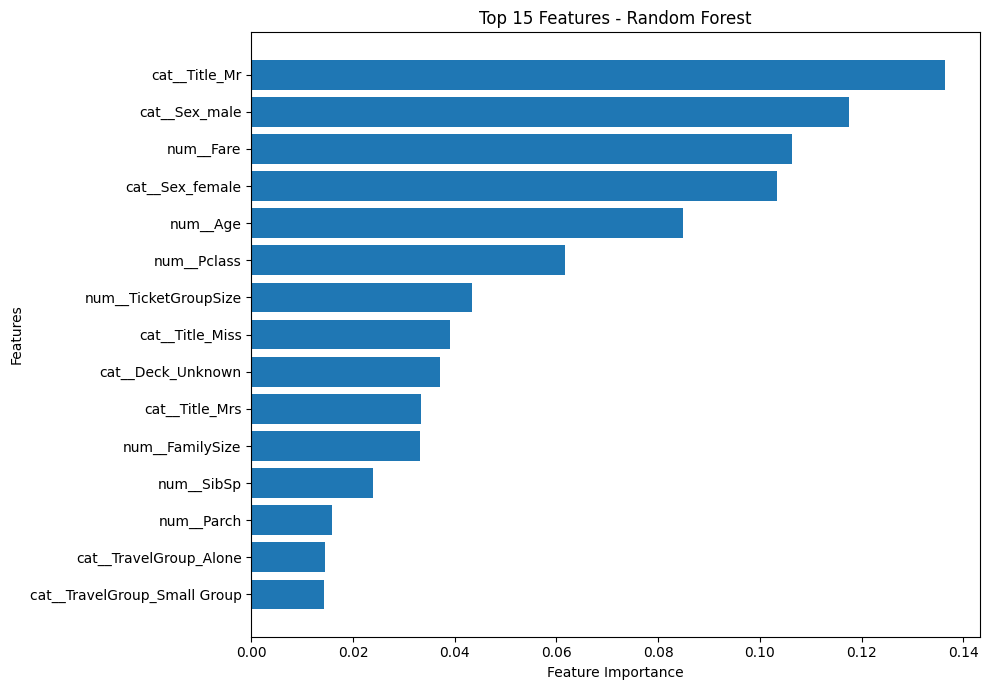

In [63]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Top 15 Features - Random Forest')
plt.tight_layout()
plt.show()

## Feature Redundancy Analysis

Some engineered features may contain overlapping information.

For example, FamilySize is derived from SibSp and Parch, while TravelGroup is derived from TicketGroupSize.

We will investigate numerical feature correlations to identify potential redundancy.

Correlation does not necessarily mean that one feature should be removed. We will use the findings to guide subsequent experiments.

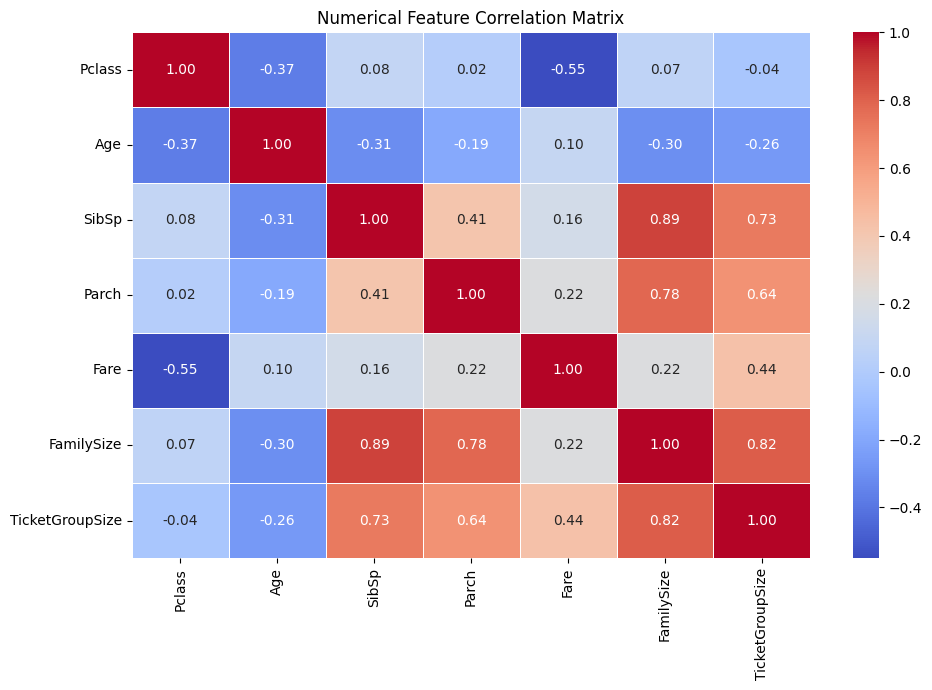

In [64]:
# Select numerical features
correlation_data = X[numerical_features]

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

# Visualise correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Numerical Feature Correlation Matrix')
plt.tight_layout()
plt.show()

Highly Correlated Pairs

In [65]:
# Extract upper triangle of correlation matrix
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find feature pairs with correlation above 0.70
high_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlations.columns = [
    'Feature 1',
    'Feature 2',
    'Correlation'
]

high_correlations = high_correlations[
    high_correlations['Correlation'].abs() > 0.70
]

print("Highly correlated feature pairs:")
print(high_correlations.to_string(index=False))

Highly correlated feature pairs:
 Feature 1       Feature 2  Correlation
     SibSp      FamilySize     0.890712
     SibSp TicketGroupSize     0.727331
     Parch      FamilySize     0.783111
FamilySize TicketGroupSize     0.816020


## Feature Ablation Experiment

Feature ablation is an experimental technique used to determine the contribution of individual features or feature groups to model performance.

We will compare different feature configurations using identical cross-validation folds.

Our objective is to determine whether removing redundant features improves, reduces or maintains predictive accuracy.

In [66]:
# Define experimental feature groups

family_features = [
    'SibSp',
    'Parch',
    'FamilySize'
]

travel_features = [
    'TicketGroupSize',
    'TravelGroup'
]

gender_title_features = [
    'Sex',
    'Title'
]

print("Family features:", family_features)
print("Travel features:", travel_features)
print("Gender/title features:", gender_title_features)

Family features: ['SibSp', 'Parch', 'FamilySize']
Travel features: ['TicketGroupSize', 'TravelGroup']
Gender/title features: ['Sex', 'Title']


In [67]:
feature_experiments = {
    'All Features': X.columns.tolist(),

    'FamilySize Only': [
        col for col in X.columns
        if col not in ['SibSp', 'Parch']
    ],

    'SibSp and Parch Only': [
        col for col in X.columns
        if col != 'FamilySize'
    ],

    'Without Travel Features': [
        col for col in X.columns
        if col not in ['TicketGroupSize', 'TravelGroup']
    ]
}

for experiment, features in feature_experiments.items():
    print(f"{experiment}: {len(features)} features")

All Features: 14 features
FamilySize Only: 12 features
SibSp and Parch Only: 13 features
Without Travel Features: 12 features


In [68]:
ablation_results = []

for experiment, features in feature_experiments.items():

    numerical_subset = [
        col for col in numerical_features
        if col in features
    ]

    categorical_subset = [
        col for col in categorical_features
        if col in features
    ]

    experiment_preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_transformer, numerical_subset),
            ('cat', categorical_transformer, categorical_subset)
        ]
    )

    experiment_model = Pipeline(steps=[
        ('preprocessor', experiment_preprocessor),
        ('classifier', RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            min_samples_split=5,
            min_samples_leaf=2,
            n_jobs=-1
        ))
    ])

    scores = cross_val_score(
        experiment_model,
        X[features],
        y,
        cv=cv,
        scoring='accuracy'
    )

    ablation_results.append({
        'Experiment': experiment,
        'Mean Accuracy': scores.mean(),
        'Standard Deviation': scores.std()
    })

ablation_df = pd.DataFrame(ablation_results)

ablation_df = ablation_df.sort_values(
    by='Mean Accuracy',
    ascending=False
)

print(ablation_df.to_string(index=False))

             Experiment  Mean Accuracy  Standard Deviation
        FamilySize Only       0.840619            0.014572
   SibSp and Parch Only       0.838384            0.011985
           All Features       0.838372            0.011055
Without Travel Features       0.836125            0.009225


## Hyperparameter Optimisation

Hyperparameter optimisation is the process of finding suitable model configuration settings that improve predictive performance.

We will use RandomizedSearchCV to explore different Random Forest configurations.

The search will use stratified five-fold cross-validation and accuracy as the evaluation metric.

All preprocessing operations will remain inside the machine learning pipeline to prevent data leakage.

In [69]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Select the best feature configuration from our ablation experiment
selected_features = feature_experiments['FamilySize Only']

X_selected = X[selected_features]

# Identify numerical and categorical features
selected_numerical = [
    col for col in numerical_features
    if col in selected_features
]

selected_categorical = [
    col for col in categorical_features
    if col in selected_features
]

# Create preprocessing pipeline
selected_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, selected_numerical),
        ('cat', categorical_transformer, selected_categorical)
    ]
)

# Build Random Forest pipeline
tuning_pipeline = Pipeline(steps=[
    ('preprocessor', selected_preprocessor),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

print("Hyperparameter optimisation pipeline created.")

Hyperparameter optimisation pipeline created.


In [70]:
param_distributions = {
    'classifier__n_estimators': randint(100, 601),
    'classifier__max_depth': [None, 3, 5, 7, 10, 15, 20],
    'classifier__min_samples_split': randint(2, 16),
    'classifier__min_samples_leaf': randint(1, 9),
    'classifier__max_features': ['sqrt', 'log2', None],
    'classifier__class_weight': [None, 'balanced']
}

print("Hyperparameter search space defined.")

Hyperparameter search space defined.


In [71]:
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=40,
    scoring='accuracy',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_selected, y)

print("\nBest Cross-Validation Accuracy:")
print(random_search.best_score_)

print("\nBest Hyperparameters:")
print(random_search.best_params_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits

Best Cross-Validation Accuracy:
0.8406000878789781

Best Hyperparameters:
{'classifier__class_weight': None, 'classifier__max_depth': None, 'classifier__max_features': None, 'classifier__min_samples_leaf': 6, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 215}


Training selected Model

In [72]:
# Build the final Random Forest pipeline

final_model = Pipeline(steps=[
    ('preprocessor', selected_preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        min_samples_split=5,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

# Train using the complete training dataset
final_model.fit(X_selected, y)

print("Final model trained successfully.")

Final model trained successfully.


In [73]:
# Select matching features from the test dataset
X_test_selected = X_test[selected_features]

# Generate predictions
final_predictions = final_model.predict(X_test_selected)

print("Predictions generated:", len(final_predictions))

Predictions generated: 418


In [74]:
final_submission = pd.DataFrame({
    'PassengerId': test_passenger_ids,
    'Survived': final_predictions
})

final_submission.to_csv(
    'titanic_submission.csv',
    index=False
)

print(final_submission.head())

print("\nSubmission shape:", final_submission.shape)

print("\nPrediction distribution:")
print(final_submission['Survived'].value_counts())

print("\nSubmission file saved successfully.")

     PassengerId  Survived
891          892         0
892          893         1
893          894         0
894          895         0
895          896         1

Submission shape: (418, 2)

Prediction distribution:
Survived
0    263
1    155
Name: count, dtype: int64

Submission file saved successfully.


In [75]:
# Verify submission format
print("Rows:", len(final_submission))
print("Columns:", final_submission.columns.tolist())

print("\nFirst five rows:")
print(final_submission.head())

print("\nMissing values:")
print(final_submission.isnull().sum())

assert len(final_submission) == 418
assert list(final_submission.columns) == ['PassengerId', 'Survived']
assert final_submission.isnull().sum().sum() == 0
assert final_submission['Survived'].isin([0, 1]).all()

print("\nSubmission file is valid!")

Rows: 418
Columns: ['PassengerId', 'Survived']

First five rows:
     PassengerId  Survived
891          892         0
892          893         1
893          894         0
894          895         0
895          896         1

Missing values:
PassengerId    0
Survived       0
dtype: int64

Submission file is valid!
